In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

In [78]:
image = cv2.imread('sar_2.jpg')
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY) 

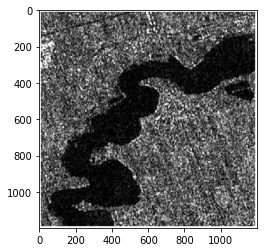

In [5]:
plt.imshow(image_gray, cmap="gray")

# Точечная бинаризация

In [52]:
import copy

bin_img = copy.deepcopy(image_gray)
T  = 50
bin_img[image_gray < T] = 0
bin_img[image_gray >= T] = 255

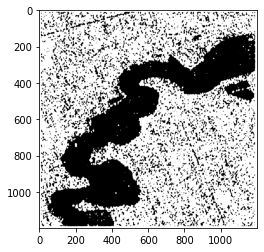

In [53]:
plt.imshow(bin_img, cmap="gray")

# Бинаризация Отсу

In [7]:
# otsu binarization
_,th2 = cv2.threshold(image_gray,0,255,cv2.THRESH_BINARY+cv2.THRESH_OTSU)

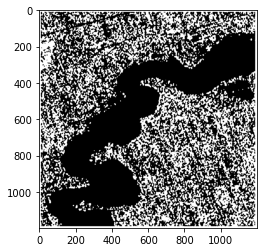

In [8]:
plt.imshow(th2, cmap="gray")

# Адаптивная бинаризация

In [42]:
# 
th3 = cv2.adaptiveThreshold(image_gray,255,cv2.ADAPTIVE_THRESH_GAUSSIAN_C,\
            cv2.THRESH_BINARY,71,21)


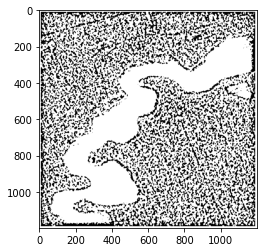

In [43]:
plt.imshow(th3, cmap="gray")

# Оператор Собеля

In [55]:
scale = 1
delta = 0
ddepth = cv2.CV_16S
grad_x = cv2.Sobel(image_gray, ddepth, 1, 0, ksize=3, scale=scale, delta=delta, borderType=cv2.BORDER_DEFAULT)
grad_y = cv2.Sobel(image_gray, ddepth, 0, 1, ksize=3, scale=scale, delta=delta, borderType=cv2.BORDER_DEFAULT)

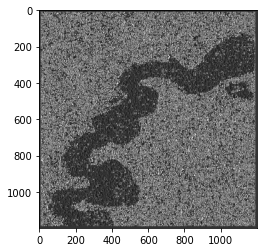

In [57]:
plt.imshow((grad_x - grad_x.min())*255, cmap="gray")

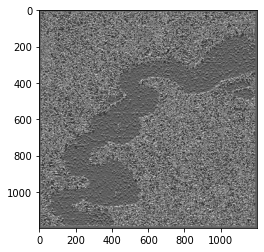

In [58]:
plt.imshow((grad_y - grad_y.min())*255, cmap="gray")

In [60]:
grad = cv2.addWeighted(grad_x, 0.5, grad_y, 0.5,0.0) # mean value between

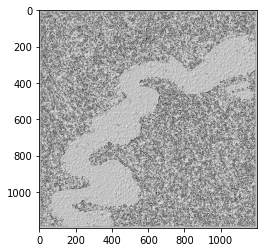

In [62]:
plt.imshow((grad - grad.min())*255, cmap="gray")

# Canny

In [64]:
edges = cv2.Canny(image_gray,100,200)

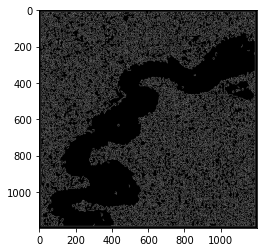

In [65]:
plt.imshow(edges, cmap="gray")

# Преобразование Хафа

In [127]:
image = cv2.imread('img_1.jpg')
image = cv2.cvtColor(image, cv2.COLOR_RGB2BGR) 
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY) 

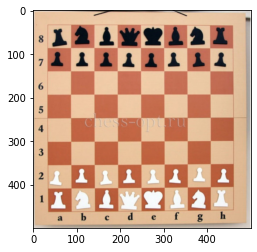

In [128]:
plt.imshow(image)

In [138]:
canny = cv2.Canny(image_gray,50,150,apertureSize = 3)

In [146]:
lines = cv2.HoughLines(canny, 1, np.pi / 180, 190)

In [147]:
import math 

if lines is not None:
        for i in range(0, len(lines)):
            rho = lines[i][0][0]
            theta = lines[i][0][1]
            a = math.cos(theta)
            b = math.sin(theta)
            x0 = a * rho
            y0 = b * rho
            pt1 = (int(x0 + 1000*(-b)), int(y0 + 1000*(a)))
            pt2 = (int(x0 - 1000*(-b)), int(y0 - 1000*(a)))
            cv2.line(image, pt1, pt2, (0,0,255), 3, cv2.LINE_AA)

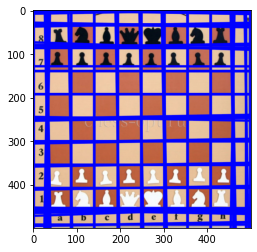

In [148]:
plt.imshow(image)

In [149]:
#ДЗ 
# 1. Для изображения sar_3.jpg найти наиболее протяженный участок
# (выделить линии при помощи преобразования Хафа)
# 2. Для изображения sar_3.jpg провести исследование алгоритмов бинаризации, выделить участок дорожной полосы.

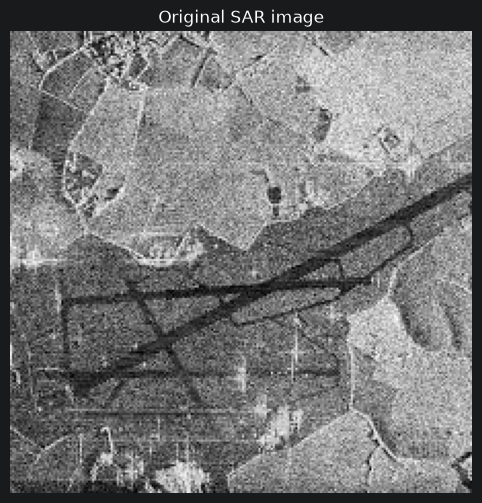

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

image_sar = cv2.imread('sar_3.jpg')

if image_sar is None:
    raise FileNotFoundError('Не найден файл sar_3.jpg')

image_sar_rgb = cv2.cvtColor(image_sar, cv2.COLOR_BGR2RGB)
image_sar_gray = cv2.cvtColor(image_sar, cv2.COLOR_BGR2GRAY)

plt.figure(figsize=(10, 6))
plt.imshow(image_sar_rgb)
plt.title('Original SAR image')
plt.axis('off')
plt.show()

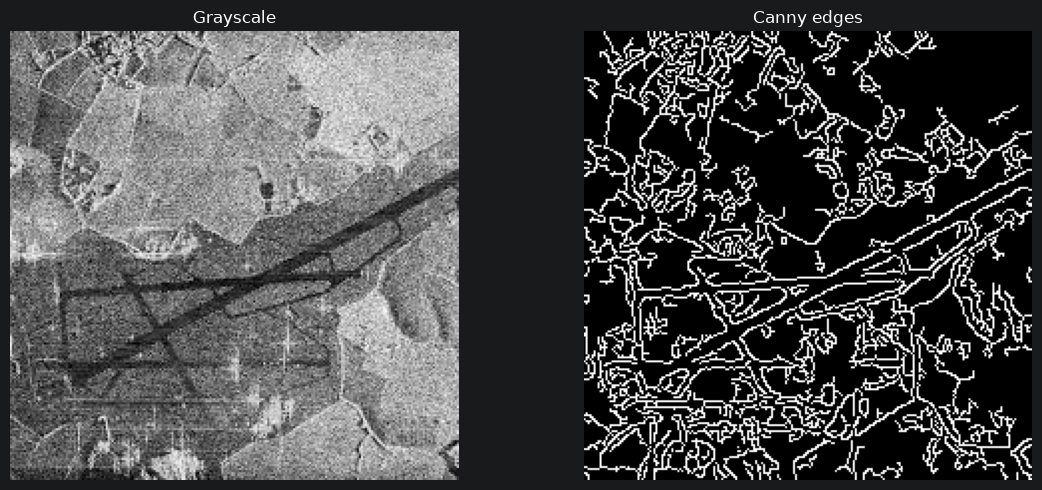

In [2]:
sar_blur = cv2.GaussianBlur(image_sar_gray, (5, 5), 0)

sar_edges = cv2.Canny(sar_blur, 50, 150)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image_sar_gray, cmap='gray')
plt.title('Grayscale')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(sar_edges, cmap='gray')
plt.title('Canny edges')
plt.axis('off')

plt.tight_layout()
plt.show()

Найдено отрезков: 15


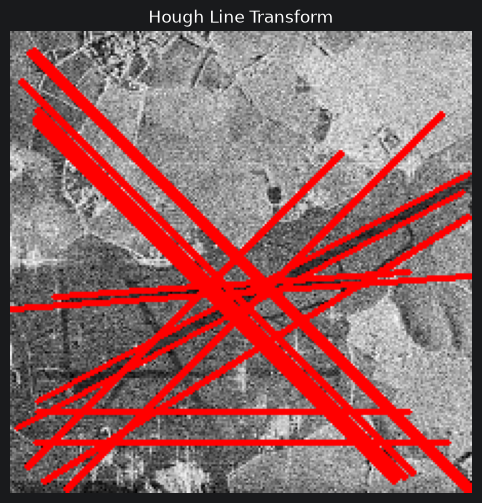

In [4]:

lines_sar = cv2.HoughLinesP(
    sar_edges,
    rho=1,
    theta=np.pi / 180,
    threshold=80,
    minLineLength=100,
    maxLineGap=30
)

sar_lines_image = image_sar_rgb.copy()

if lines_sar is not None:
    lines_sar = lines_sar.reshape(-1, 4)

    for x1, y1, x2, y2 in lines_sar:
        cv2.line(
            sar_lines_image,
            (int(x1), int(y1)),
            (int(x2), int(y2)),
            (255, 0, 0),
            2
        )

    print(f'Найдено отрезков: {len(lines_sar)}')
else:
    print('Линии не обнаружены')

plt.figure(figsize=(10, 6))
plt.imshow(sar_lines_image)
plt.title('Hough Line Transform')
plt.axis('off')
plt.show()

Длина самого длинного отрезка: 302.64 пикселей


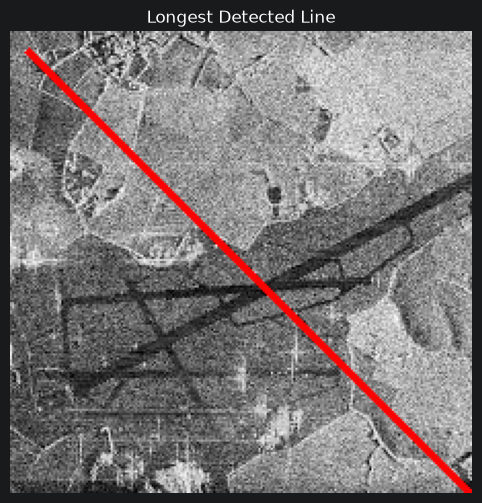

In [5]:

sar_longest_image = image_sar_rgb.copy()

if lines_sar is not None:
    longest_line = max(
        lines_sar,
        key=lambda line: np.hypot(
            line[2] - line[0],
            line[3] - line[1]
        )
    )

    x1, y1, x2, y2 = map(int, longest_line)

    length = np.hypot(x2 - x1, y2 - y1)

    cv2.line(
        sar_longest_image,
        (x1, y1),
        (x2, y2),
        (255, 0, 0),
        4
    )

    print(f'Длина самого длинного отрезка: {length:.2f} пикселей')
else:
    print('Линии не обнаружены')

plt.figure(figsize=(10, 6))
plt.imshow(sar_longest_image)
plt.title('Longest Detected Line')
plt.axis('off')
plt.show()

Подходящих отрезков: 7
Длина отрезка: 245.59 пикселей


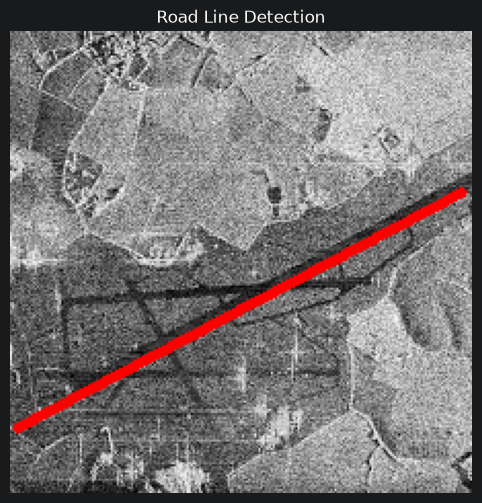

In [7]:
sar_road_image = image_sar_rgb.copy()

road_lines = []

if lines_sar is not None:
    for x1, y1, x2, y2 in lines_sar.reshape(-1, 4):

        dx = x2 - x1
        dy = y2 - y1

        length = np.hypot(dx, dy)

        angle = np.degrees(np.arctan2(dy, dx))

        if abs(angle) < 35 or abs(angle) > 145:
            road_lines.append((length, x1, y1, x2, y2))

    print(f'Подходящих отрезков: {len(road_lines)}')

    if road_lines:
        length, x1, y1, x2, y2 = max(road_lines)

        cv2.line(
            sar_road_image,
            (int(x1), int(y1)),
            (int(x2), int(y2)),
            (255, 0, 0),
            3
        )

        print(f'Длина отрезка: {length:.2f} пикселей')
    else:
        print('Подходящие отрезки не найдены')

plt.figure(figsize=(10, 6))
plt.imshow(sar_road_image)
plt.title('Road Line Detection')
plt.axis('off')
plt.show()

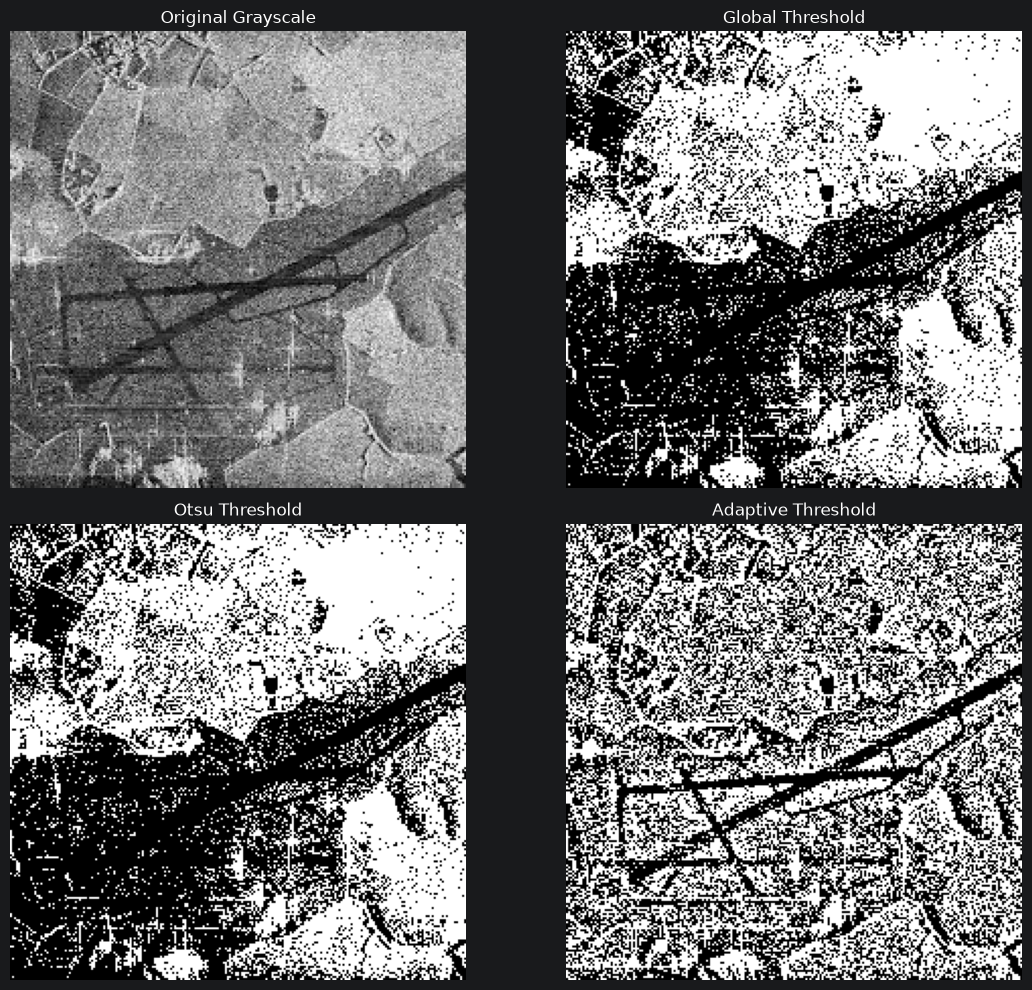

In [8]:

# Исследование алгоритмов бинаризации

# 1. Глобальная бинаризация
_, binary_global = cv2.threshold(
    image_sar_gray, 127, 255, cv2.THRESH_BINARY
)

# 2. Бинаризация методом Оцу
_, binary_otsu = cv2.threshold(
    image_sar_gray, 0, 255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

# 3. Адаптивная бинаризация
binary_adaptive = cv2.adaptiveThreshold(
    image_sar_gray,
    255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY,
    31,
    5
)

# Отображение результатов
plt.figure(figsize=(12, 10))

plt.subplot(2, 2, 1)
plt.imshow(image_sar_gray, cmap='gray')
plt.title('Original Grayscale')
plt.axis('off')

plt.subplot(2, 2, 2)
plt.imshow(binary_global, cmap='gray')
plt.title('Global Threshold')
plt.axis('off')

plt.subplot(2, 2, 3)
plt.imshow(binary_otsu, cmap='gray')
plt.title('Otsu Threshold')
plt.axis('off')

plt.subplot(2, 2, 4)
plt.imshow(binary_adaptive, cmap='gray')
plt.title('Adaptive Threshold')
plt.axis('off')

plt.tight_layout()
plt.show()


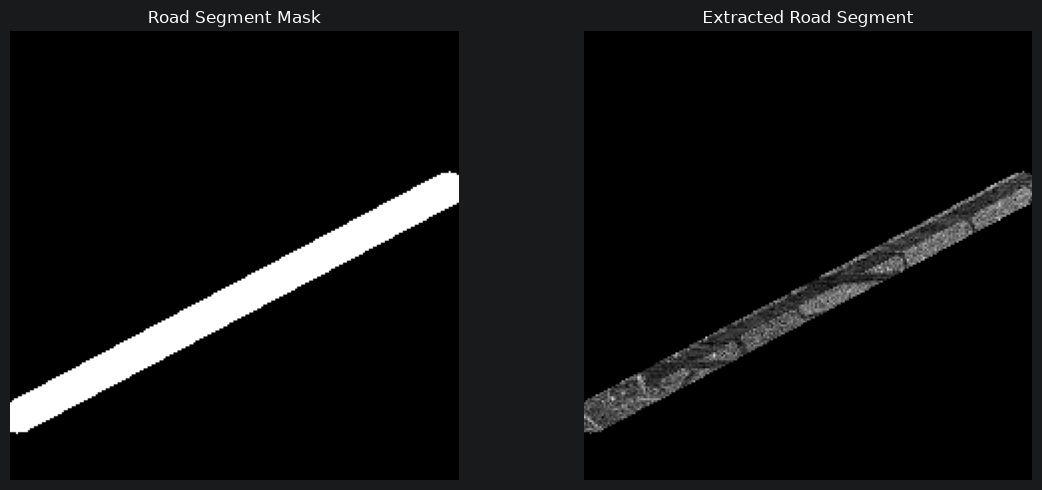

In [9]:
road_mask = np.zeros_like(image_sar_gray)

if road_lines:
    length, x1, y1, x2, y2 = max(road_lines)

    cv2.line(
        road_mask,
        (int(x1), int(y1)),
        (int(x2), int(y2)),
        255,
        15
    )

    road_segment = cv2.bitwise_and(
        image_sar_rgb,
        image_sar_rgb,
        mask=road_mask
    )

    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    plt.imshow(road_mask, cmap='gray')
    plt.title('Road Segment Mask')
    plt.axis('off')

    plt.subplot(1, 2, 2)
    plt.imshow(road_segment)
    plt.title('Extracted Road Segment')
    plt.axis('off')

    plt.tight_layout()
    plt.show()

else:
    print('Подходящие участки дороги не найдены')


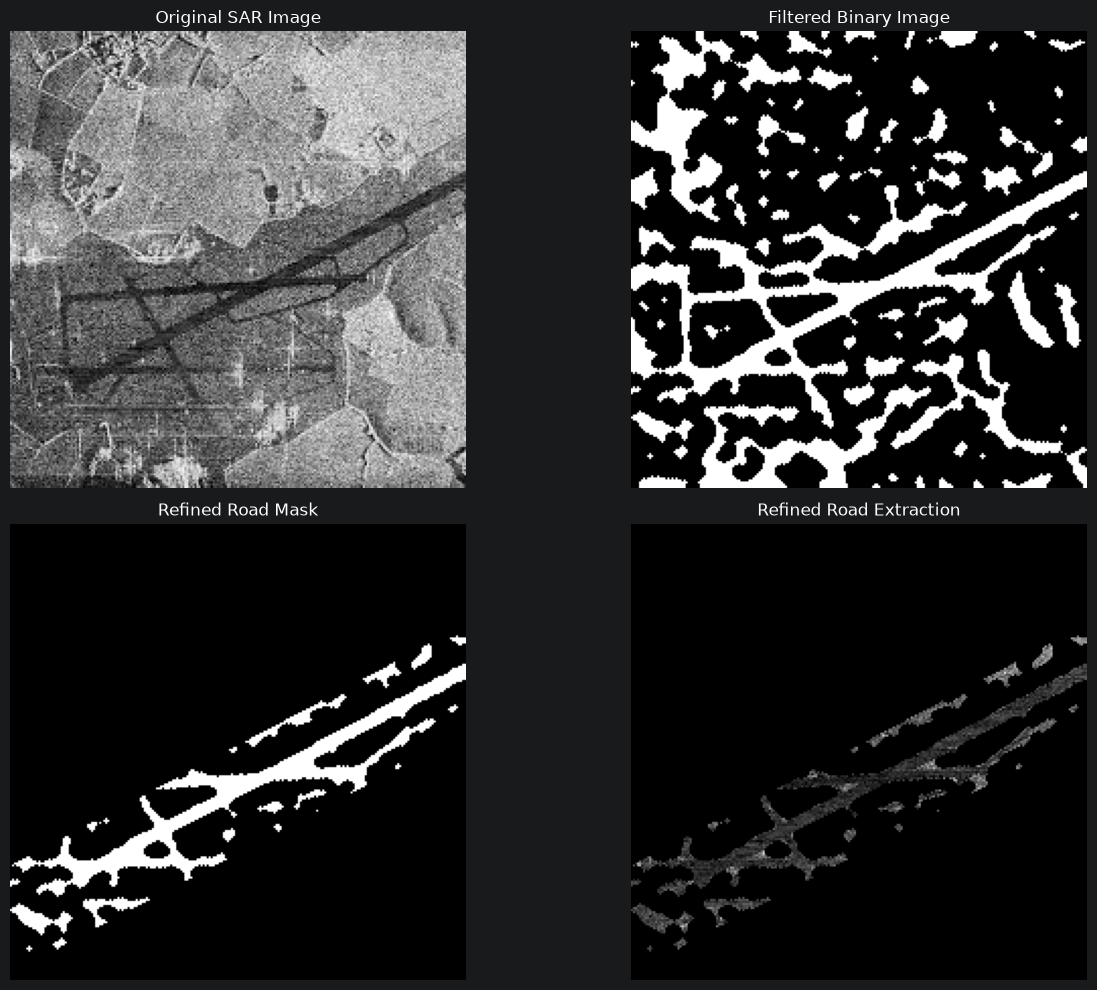

In [10]:

# Улучшенное выделение дорожной полосы


sar_filtered = cv2.bilateralFilter(image_sar_gray, 9, 60, 60)


road_binary = cv2.adaptiveThreshold(
    sar_filtered,
    255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY_INV,
    31,
    5
)


kernel = cv2.getStructuringElement(
    cv2.MORPH_ELLIPSE, (3, 3)
)

road_clean = cv2.morphologyEx(
    road_binary, cv2.MORPH_OPEN, kernel
)

road_clean = cv2.morphologyEx(
    road_clean,
    cv2.MORPH_CLOSE,
    cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE, (7, 7)
    )
)

road_roi = np.zeros_like(image_sar_gray)

if road_lines:
    _, x1, y1, x2, y2 = max(road_lines)

    cv2.line(
        road_roi,
        (int(x1), int(y1)),
        (int(x2), int(y2)),
        255,
        45
    )

road_mask_refined = cv2.bitwise_and(
    road_clean, road_roi
)

road_result_refined = cv2.bitwise_and(
    image_sar_rgb,
    image_sar_rgb,
    mask=road_mask_refined
)

plt.figure(figsize=(14, 10))

plt.subplot(2, 2, 1)
plt.imshow(image_sar_gray, cmap='gray')
plt.title('Original SAR Image')
plt.axis('off')

plt.subplot(2, 2, 2)
plt.imshow(road_clean, cmap='gray')
plt.title('Filtered Binary Image')
plt.axis('off')

plt.subplot(2, 2, 3)
plt.imshow(road_mask_refined, cmap='gray')
plt.title('Refined Road Mask')
plt.axis('off')

plt.subplot(2, 2, 4)
plt.imshow(road_result_refined)
plt.title('Refined Road Extraction')
plt.axis('off')

plt.tight_layout()
plt.show()


Вывод

В ходе работы было обработано радиолокационное изображение 'sar_3.jpg'.

С помощью преобразования Хафа были обнаружены прямолинейные участки изображения и определён наиболее протяжённый отрезок.

Проведено сравнение трёх методов бинаризации: глобальной пороговой обработки, метода Оцу и адаптивной бинаризации. Установлено, что адаптивная бинаризация позволяет лучше сохранять локальные особенности дорожных структур, однако также выделяет значительное количество шума.

Для улучшения результата применены сглаживание, морфологические операции и ограничение области обработки. В результате удалось выделить часть дорожной полосы, хотя полученная маска содержит отдельные разрывы и посторонние элементы.

Таким образом, поставленные задачи по обнаружению линейных объектов, исследованию методов бинаризации и выделению дорожного участка сделал.